# Python simulation of the integrated malaria AI–mathematical modelling framework
I recommend implementing the model in Python as a modular simulation, starting with the seven-compartment human–mosquito malaria model and then integrating climate effects, intervention controls, machine learning, optimal control and an interactive dashboard.

The code below is designed as a working research prototype. It will allow you to:
1. Simulate human and mosquito malaria transmission.
2. Incorporate temperature, rainfall and humidity.
3. Introduce bed nets, indoor residual spraying, treatment and surveillance.
4. Generate synthetic malaria surveillance data.
5. Estimate model parameters and fit a machine-learning model.
6. Compare mechanistic and hybrid AI predictions.
7. Evaluate intervention strategies.
8. Generate plots and performance statistics.


We will use synthetic data initially. You can subsequently replace these with actual malaria surveillance records from Kenya.

# 1. Install the required Python packages
Open Anaconda Prompt and run:

In [3]:
# pip install numpy pandas scipy matplotlib seaborn scikit-learn xgboost streamlit plotly

# For this first implementation, we will use:
- NumPy for numerical calculations.
- SciPy for solving differential equations.
- Pandas for data management.
- Matplotlib for visualization.
- Scikit-learn for machine learning.
- Streamlit for a future interactive dashboard.


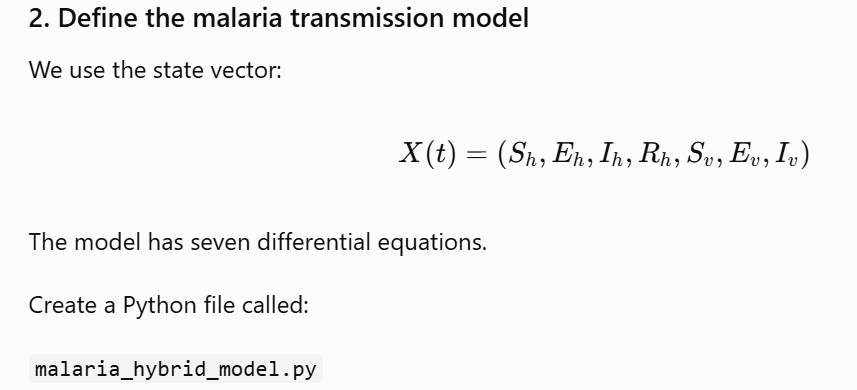

In [10]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# =====================================================
# 1. MODEL PARAMETERS
# =====================================================

params = {
    # "Lambda_h": 20,
    "Lambda_h": 50,
    "Lambda_v": 100,
    "mu_h": 1/(70*365),
    "mu_v": 1/14,
    "sigma_h": 1/12,
    "sigma_v": 1/10,
    "gamma_h": 1/14,
    "delta_h": 0.0001,
    "a0": 0.25,
    "b_vh": 0.30,
    "b_hv": 0.25,
    "T_opt": 27,
    "s_T": 8,
    "K_P": 100,
    "eta2": 0.08,
    "eta3": 0.15,
    "eta4": 0.05,
    "eps1": 0.5,
    "eps3": 0.4,
    "eps4": 0.6,
    "q0": 0.65
}

# =====================================================
# 2. CLIMATE VARIABLES
# =====================================================

def climate(t):

    temperature = 25 + 3*np.sin(2*np.pi*t/365)

    rainfall = 100 + 40*np.sin(
        2*np.pi*(t-60)/365
    )

    humidity = 65 + 10*np.sin(
        2*np.pi*t/365
    )

    return temperature, rainfall, humidity


# =====================================================
# 3. INTERVENTION CONTROLS
# =====================================================

def interventions(t, strategy="moderate"):

    if strategy == "none":
        return 0, 0, 0, 0

    elif strategy == "moderate":
        return 0.4, 0.3, 0.5, 0.4

    elif strategy == "intensive":
        return 0.8, 0.7, 0.8, 0.7

    elif strategy == "seasonal":

        u1 = 0.7 if 90 <= t <= 210 else 0.3
        u2 = 0.6 if 90 <= t <= 210 else 0.2
        u3 = 0.7
        u4 = 0.6

        return u1, u2, u3, u4

    return 0, 0, 0, 0


# =====================================================
# 4. SEIR-SEI DIFFERENTIAL EQUATIONS
# =====================================================

def malaria_model(t, y, strategy="moderate"):

    Sh, Eh, Ih, Rh, Sv, Ev, Iv = y

    p = params

    Nh = Sh + Eh + Ih + Rh

    if Nh <= 0:
        raise ValueError("Human population must be positive")

    T, P, H = climate(t)

    u1, u2, u3, u4 = interventions(t, strategy)

    # Temperature-dependent biting rate
    fT = np.exp(
        -((T-p["T_opt"])**2)/(2*p["s_T"]**2)
    )

    # Humidity effect
    fH = np.clip(H/65, 0.1, 1.5)

    a = p["a0"] * fT * fH

    # Rainfall-dependent mosquito recruitment
    fP = max(P, 0)/(p["K_P"] + max(P, 0))

    Lambda_v = p["Lambda_v"] * fP

    # Intervention-modified parameters
    beta_h = a*p["b_vh"]*(1-p["eps1"]*u1)

    beta_v = a*p["b_hv"]*(1-p["eps3"]*u3)

    mu_v = p["mu_v"] + p["eta2"]*u2

    gamma_h = (
        p["gamma_h"]
        + p["eta3"]*u3
        + p["eta4"]*u4
    )

    # Forces of infection
    lambda_h = beta_h*Iv/Nh

    lambda_v = beta_v*Ih/Nh

    # Human equations
    dSh = p["Lambda_h"] - lambda_h*Sh - p["mu_h"]*Sh

    dEh = lambda_h*Sh - (
        p["sigma_h"]+p["mu_h"]
    )*Eh

    dIh = p["sigma_h"]*Eh - (
        gamma_h+p["delta_h"]+p["mu_h"]
    )*Ih

    dRh = gamma_h*Ih - p["mu_h"]*Rh

    # Mosquito equations
    dSv = Lambda_v - lambda_v*Sv - mu_v*Sv

    dEv = lambda_v*Sv - (
        p["sigma_v"]+mu_v
    )*Ev

    dIv = p["sigma_v"]*Ev - mu_v*Iv

    return [dSh, dEh, dIh, dRh, dSv, dEv, dIv]


In [ ]:
Important modelling note: These parameters are illustrative, not estimated Kenyan epidemiological values. The simplified climate functions are starting assumptions and should eventually be replaced with biologically calibrated temperature, rainfall and humidity response functions. Also, the current model uses continuous intervention intensity rather than measured coverage.
3. Run the simulation for 365 days
We now specify the initial populations and solve the differential equations using solve_ivp.

Append the following code to the same file.

In [11]:

# =====================================================
# 5. INITIAL CONDITIONS
# =====================================================

Nh0 = 100000
Nv0 = 5000

# Make human recruitment consistent with initial population
params["Lambda_h"] = params["mu_h"] * Nh0

initial_conditions = [
    Nh0 - 100 - 20,  # Susceptible humans
    100,              # Exposed humans
    20,               # Infectious humans
    0,                # Recovered humans
    Nv0 - 50 - 10,   # Susceptible mosquitoes
    50,               # Exposed mosquitoes
    10                # Infectious mosquitoes
]

# =====================================================
# 6. SIMULATION FUNCTION
# =====================================================

def simulate_malaria(strategy="moderate", days=365):
# def simulate_malaria(strategy="moderate", days=10):

    t_eval = np.arange(days + 1)

    solution = solve_ivp(
        fun=lambda t, y: malaria_model(
            t, y, strategy
        ),
        t_span=(0, days),
        y0=initial_conditions,
        t_eval=t_eval,
        method="RK45",
        rtol=1e-7,
        atol=1e-8
    )

    if not solution.success:
        raise RuntimeError(solution.message)

    results = pd.DataFrame({
        "Day": solution.t,
        "Sh": solution.y[0],
        "Eh": solution.y[1],
        "Ih": solution.y[2],
        "Rh": solution.y[3],
        "Sv": solution.y[4],
        "Ev": solution.y[5],
        "Iv": solution.y[6]
    })

    # New human infections per day
    new_infections = []

    reported_cases = []

    for t, row in results.iterrows():

        T, P, H = climate(t)

        u1, u2, u3, u4 = interventions(
            t, strategy
        )

        fT = np.exp(
            -((T-params["T_opt"])**2) /
            (2*params["s_T"]**2)
        )

        a = params["a0"] * fT * np.clip(
            H/65, 0.1, 1.5
        )

        beta_h = a * params["b_vh"] * (
            1-params["eps1"]*u1
        )

        incidence = (
            beta_h * row["Iv"] *
            row["Sh"] /
            (row["Sh"] + row["Eh"] +
             row["Ih"] + row["Rh"])
        )

        q = params["q0"] + (
            1-params["q0"]
        )*params["eps4"]*u4

        new_infections.append(incidence)
        reported_cases.append(q*incidence)

    results["New_infections"] = new_infections
    results["Reported_cases"] = reported_cases

    return results


# =====================================================
# 7. RUN THREE INTERVENTION SCENARIOS
# =====================================================

no_control = simulate_malaria("none")
moderate = simulate_malaria("moderate")
intensive = simulate_malaria("intensive")
seasonal = simulate_malaria("seasonal")

print("Simulation completed successfully.")

print(moderate.head())


Simulation completed successfully.
   Day            Sh          Eh         Ih         Rh           Sv  \
0    0  99880.000000  100.000000  20.000000   0.000000  4940.000000   
1    1  99879.317252   92.661763  24.312929   3.705829  4528.190770   
2    2  99878.464587   86.073171  27.431163   8.026256  4153.985097   
3    3  99877.496611   80.121958  29.590984  12.782766  3813.966151   
4    4  99876.456263   74.716015  30.984624  17.832383  3505.027051   

          Ev         Iv  New_infections  Reported_cases  
0  50.000000  10.000000        0.580842        0.426338  
1  41.170595  13.417172        0.782630        0.574450  
2  33.911957  15.759769        0.923125        0.677574  
3  27.942566  17.261323        1.015259        0.745200  
4  23.031784  18.109811        1.069513        0.785023  


In [ ]:
4. Visualize the malaria transmission dynamics
We need to visualize both human and mosquito infections.

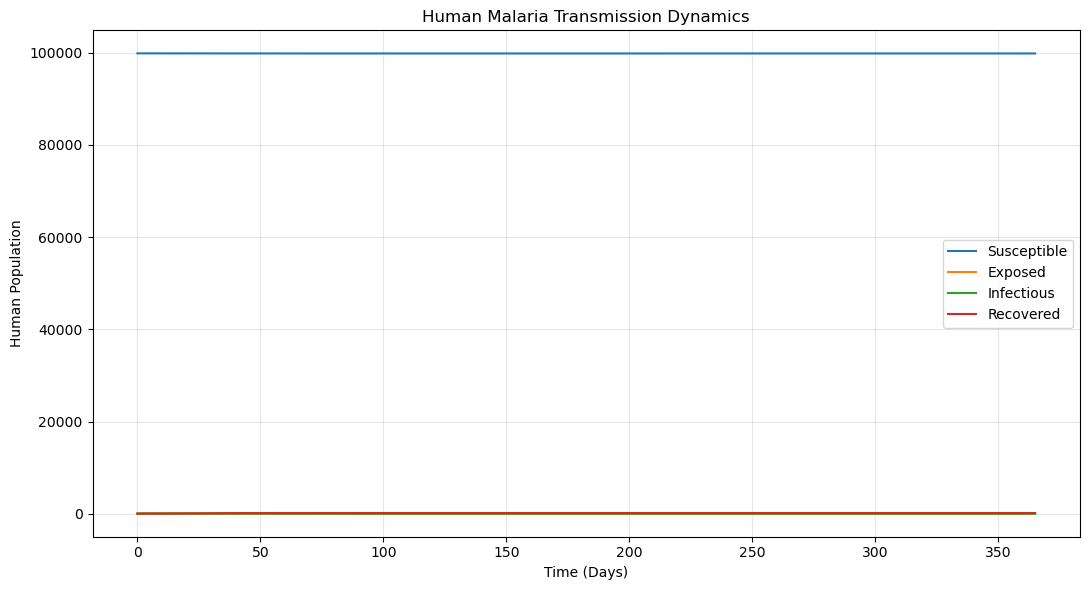

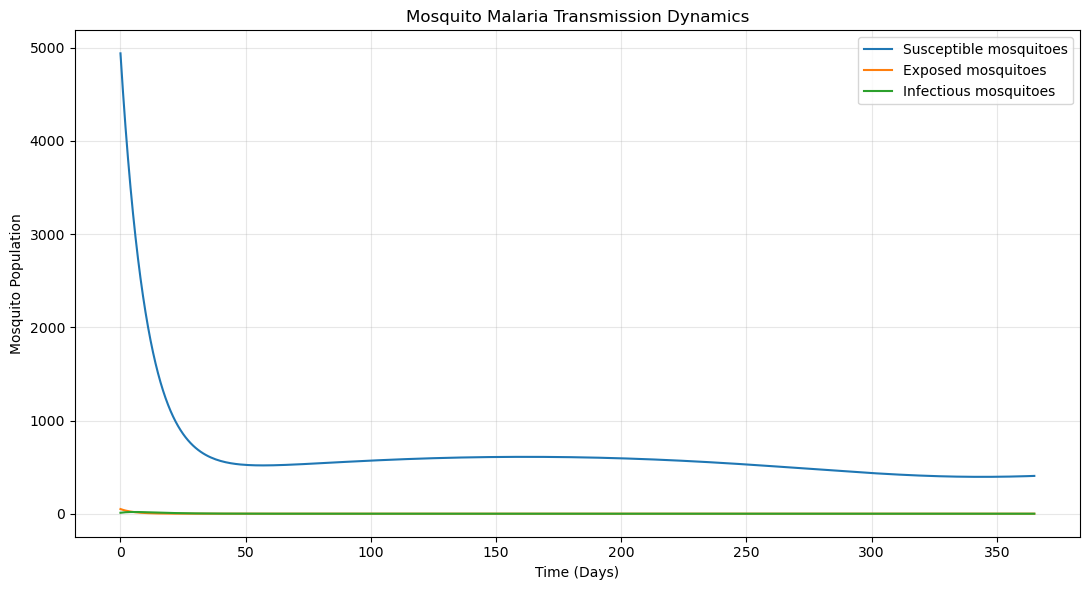

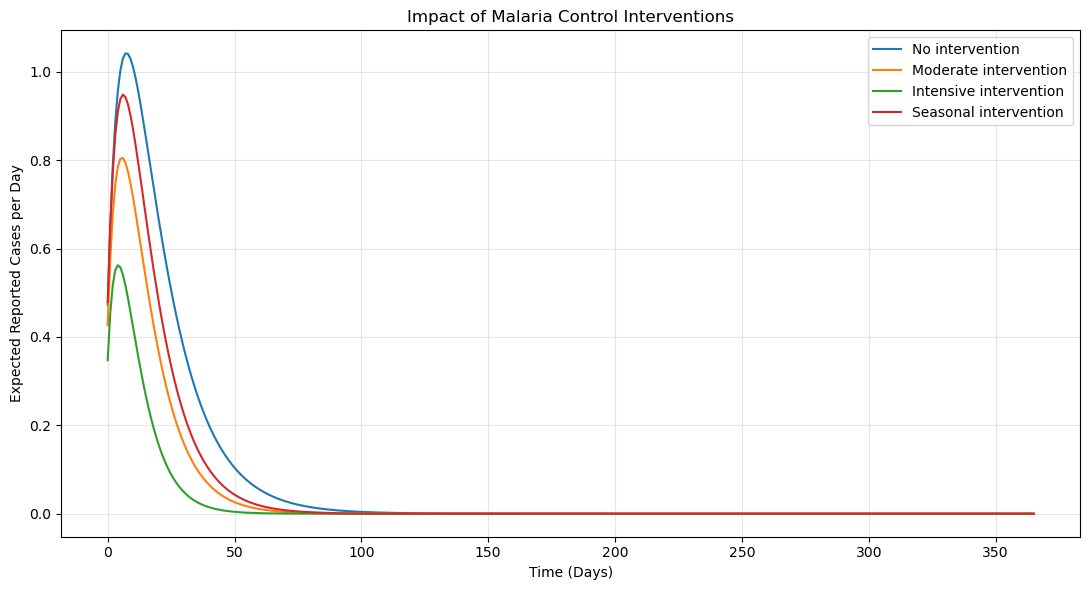

In [12]:

# =====================================================
# 8. PLOT HUMAN POPULATION
# =====================================================

plt.figure(figsize=(11, 6))

plt.plot(
    moderate["Day"],
    moderate["Sh"],
    label="Susceptible"
)

plt.plot(
    moderate["Day"],
    moderate["Eh"],
    label="Exposed"
)

plt.plot(
    moderate["Day"],
    moderate["Ih"],
    label="Infectious"
)

plt.plot(
    moderate["Day"],
    moderate["Rh"],
    label="Recovered"
)

plt.xlabel("Time (Days)")
plt.ylabel("Human Population")
plt.title("Human Malaria Transmission Dynamics")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# =====================================================
# 9. PLOT MOSQUITO POPULATION
# =====================================================

plt.figure(figsize=(11, 6))

plt.plot(
    moderate["Day"],
    moderate["Sv"],
    label="Susceptible mosquitoes"
)

plt.plot(
    moderate["Day"],
    moderate["Ev"],
    label="Exposed mosquitoes"
)

plt.plot(
    moderate["Day"],
    moderate["Iv"],
    label="Infectious mosquitoes"
)

plt.xlabel("Time (Days)")
plt.ylabel("Mosquito Population")
plt.title("Mosquito Malaria Transmission Dynamics")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# =====================================================
# 10. COMPARE INTERVENTION STRATEGIES
# =====================================================

plt.figure(figsize=(11, 6))

plt.plot(
    no_control["Day"],
    no_control["Reported_cases"],
    label="No intervention"
)

plt.plot(
    moderate["Day"],
    moderate["Reported_cases"],
    label="Moderate intervention"
)

plt.plot(
    intensive["Day"],
    intensive["Reported_cases"],
    label="Intensive intervention"
)

plt.plot(
    seasonal["Day"],
    seasonal["Reported_cases"],
    label="Seasonal intervention"
)

plt.xlabel("Time (Days)")
plt.ylabel("Expected Reported Cases per Day")

plt.title("Impact of Malaria Control Interventions")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
This will generate three important visualizations:
- Human malaria transmission dynamics.
- Mosquito population dynamics.
- Comparison of malaria cases under different intervention strategies.


    
# 5. Generate synthetic malaria surveillance data
For the AI component, we need a dataset containing observed malaria cases and associated climatic variables.

We will initially generate synthetic observations from the mechanistic model, with Poisson sampling to represent variation in reported case counts.

In [13]:

# =====================================================
# 11. GENERATE SYNTHETIC SURVEILLANCE DATA
# =====================================================

data = moderate.copy()

data["Temperature"] = [
    climate(t)[0] for t in data["Day"]
]

data["Rainfall"] = [
    climate(t)[1] for t in data["Day"]
]

data["Humidity"] = [
    climate(t)[2] for t in data["Day"]
]

rng = np.random.default_rng(42)

# Simulated observed case counts
data["Observed_cases"] = rng.poisson(
    np.maximum(data["Reported_cases"], 0)
)

# Add lagged surveillance information
data["Cases_lag1"] = (
    data["Observed_cases"].shift(1)
)

data["Cases_lag7"] = (
    data["Observed_cases"].shift(7)
)

data["Rainfall_lag7"] = (
    data["Rainfall"].shift(7)
)

data["Cases_rolling7"] = (
    data["Observed_cases"]
    .shift(1)
    .rolling(7)
    .mean()
)

data = data.dropna().reset_index(drop=True)

# Save dataset
data.to_csv(
    "malaria_surveillance_data.csv",
    index=False
)

print(data.head())

print("Dataset saved successfully.")


   Day            Sh         Eh         Ih         Rh           Sv         Ev  \
0    7  99873.199292  61.077161  31.990945  33.712345  2737.699715  12.924532   
1    8  99872.135286  57.216959  31.616734  39.007583  2527.282853  10.668142   
2    9  99871.103636  53.634474  31.014781  44.220538  2336.165097   8.808996   
3   10  99870.112051  50.300114  30.240147  49.318055  2162.592098   7.276694   
4   11  99869.165751  47.189035  29.337367  54.275236  2004.969037   6.013392   

          Iv  New_infections  Reported_cases  Temperature   Rainfall  \
0  18.101706        1.081831        0.794064    25.360624  68.362174   
1  17.574062        1.054355        0.773896    25.411836  68.788166   
2  16.899097        1.017720        0.747006    25.462926  69.223407   
3  16.124585        0.974717        0.715442    25.513879  69.667768   
4  15.287868        0.927550        0.680822    25.564680  70.121116   

    Humidity  Observed_cases  Cases_lag1  Cases_lag7  Rainfall_lag7  \
0  66.202

The generated CSV file is: <malaria_surveillance_data.csv>

For the final research, replace the simulated observations with actual weekly or daily malaria records. Use consistent reporting intervals and account for delayed reporting.

# 6. Develop the machine learning model
We will use Random Forest regression to predict malaria cases.

The model will use:
- Temperature.
- Rainfall.
- Humidity.
- Previous malaria cases.
- Recent malaria trends.
We will use chronological training and testing, with the first 80% for training and the final 20% for testing.

RANDOM FOREST PERFORMANCE
MAE: 0.949376777029555
RMSE: 0.9843846798527272
R-squared: 0.0


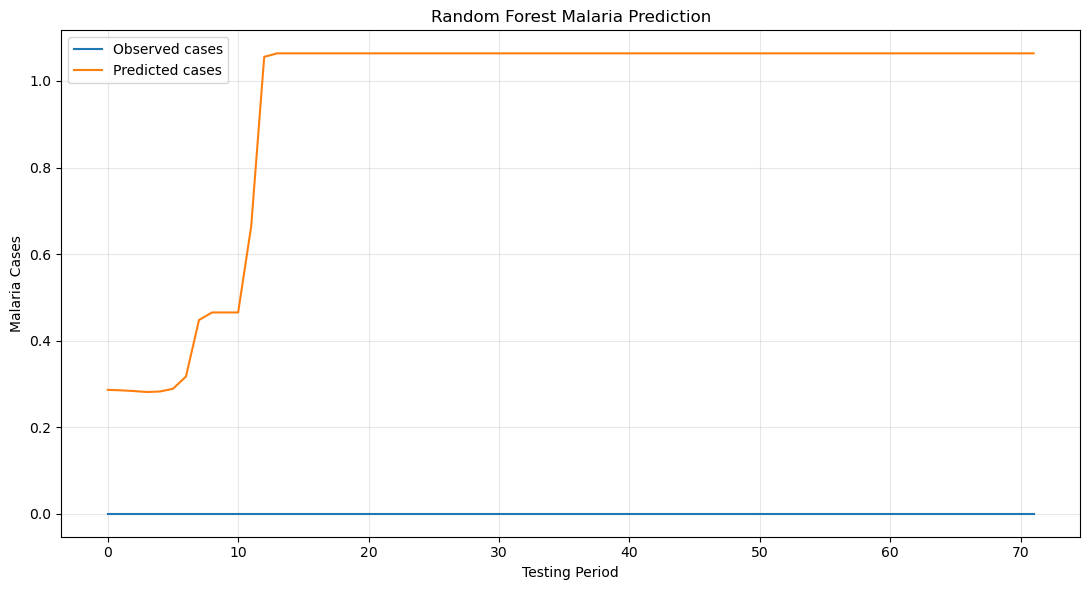

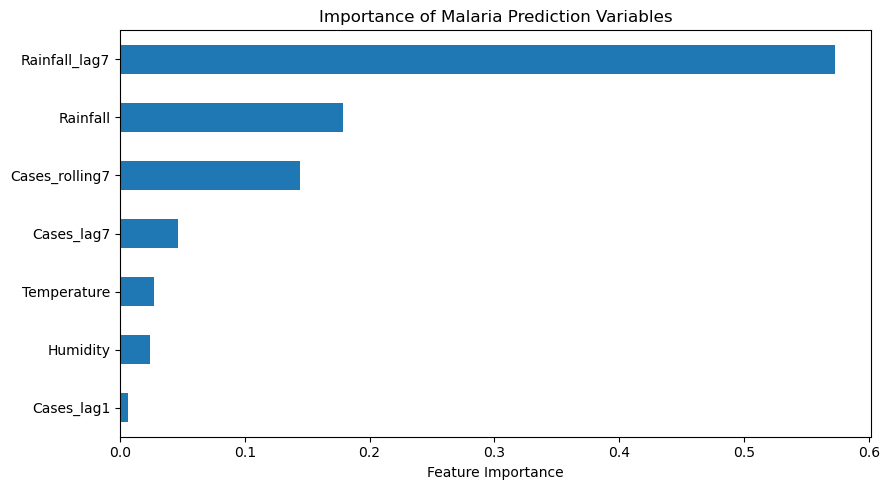

In [14]:

# =====================================================
# 12. RANDOM FOREST MALARIA PREDICTION
# =====================================================

features = [
    "Temperature",
    "Rainfall",
    "Humidity",
    "Cases_lag1",
    "Cases_lag7",
    "Rainfall_lag7",
    "Cases_rolling7"
]

X = data[features]

y = data["Observed_cases"]

split = int(0.8 * len(data))

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train model
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=8,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Predictions
y_pred = rf_model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

r2 = r2_score(y_test, y_pred)

print("RANDOM FOREST PERFORMANCE")

print("MAE:", mae)
print("RMSE:", rmse)
print("R-squared:", r2)


# Plot predictions
plt.figure(figsize=(11, 6))

plt.plot(
    y_test.values,
    label="Observed cases"
)

plt.plot(
    y_pred,
    label="Predicted cases"
)

plt.xlabel("Testing Period")
plt.ylabel("Malaria Cases")

plt.title("Random Forest Malaria Prediction")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Feature importance
importance = pd.Series(
    rf_model.feature_importances_,
    index=features
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Importance of Malaria Prediction Variables")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()


7. Develop the hybrid mathematical–AI prediction model
This is the central component of your proposed research.

Instead of allowing machine learning to replace the differential equation model, we use it to correct the prediction errors of the mechanistic model.

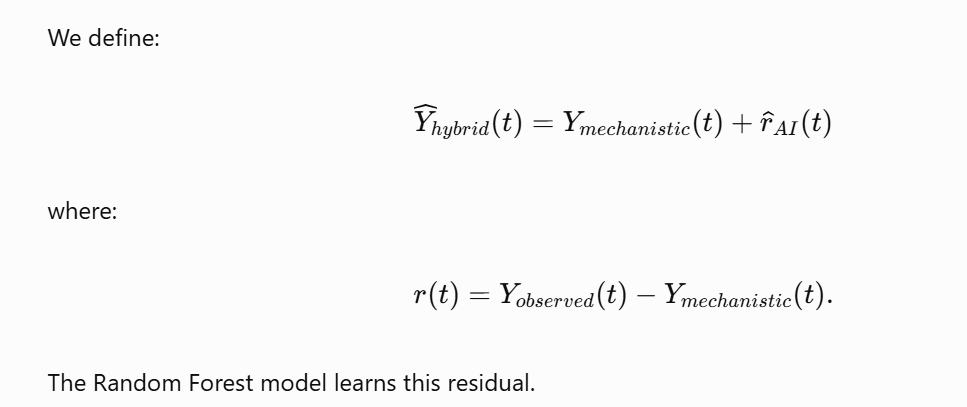

HYBRID MODEL PERFORMANCE
MAE: 0.4751232163816823
RMSE: 0.4968574550987074
R-squared: 0.0


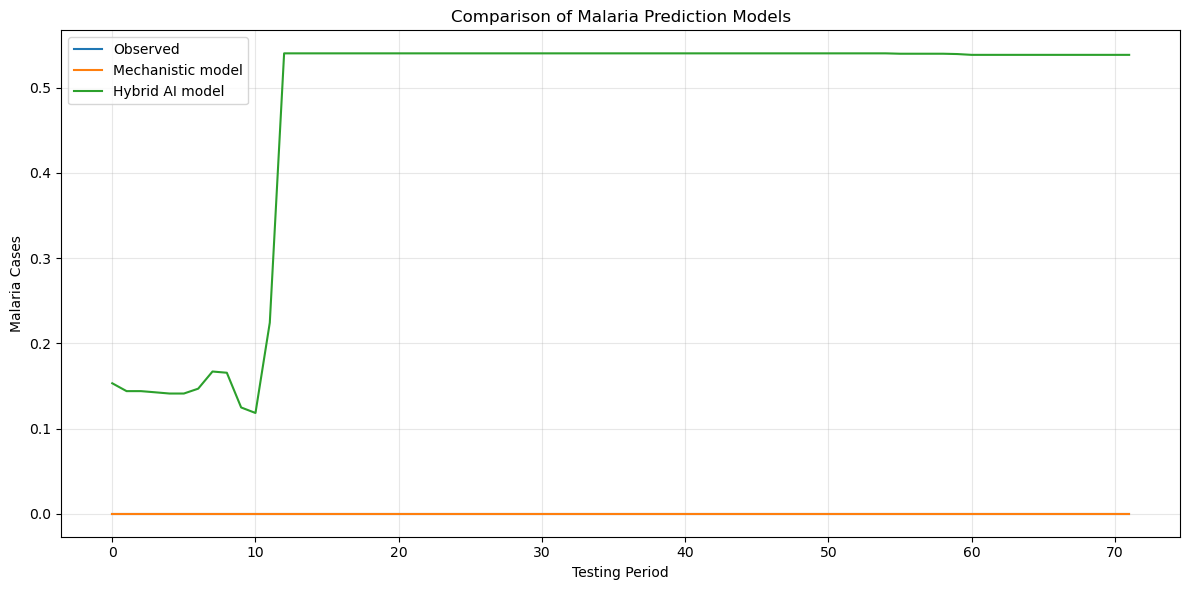

In [15]:

# =====================================================
# 13. HYBRID MECHANISTIC + AI MODEL
# =====================================================

# Mechanistic prediction
mechanistic = data["Reported_cases"].values

# Calculate residuals
residuals = (
    data["Observed_cases"].values -
    mechanistic
)

# Chronological training and testing
X_train = X.iloc[:split]
X_test = X.iloc[split:]

r_train = residuals[:split]

# Train AI residual model
hybrid_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=6,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1
)

hybrid_model.fit(X_train, r_train)

# Predict residuals
residual_pred = hybrid_model.predict(X_test)

# Combine mechanistic and AI predictions
mechanistic_test = mechanistic[split:]

hybrid_prediction = np.maximum(
    0,
    mechanistic_test + residual_pred
)

# Evaluate hybrid model
hybrid_mae = mean_absolute_error(
    y_test,
    hybrid_prediction
)

hybrid_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        hybrid_prediction
    )
)

hybrid_r2 = r2_score(
    y_test,
    hybrid_prediction
)

print("HYBRID MODEL PERFORMANCE")

print("MAE:", hybrid_mae)
print("RMSE:", hybrid_rmse)
print("R-squared:", hybrid_r2)


# Compare the two models
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Observed"
)

plt.plot(
    mechanistic_test,
    label="Mechanistic model"
)

plt.plot(
    hybrid_prediction,
    label="Hybrid AI model"
)

plt.title("Comparison of Malaria Prediction Models")

plt.xlabel("Testing Period")
plt.ylabel("Malaria Cases")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
This allows you to investigate whether the hybrid model improves prediction accuracy compared with the mechanistic and standalone AI models.

Note that the synthetic observations here are generated from the same mechanistic model. This is useful for testing the software pipeline, but it does not demonstrate real-world superiority of the hybrid model. That must be established using independent surveillance data.

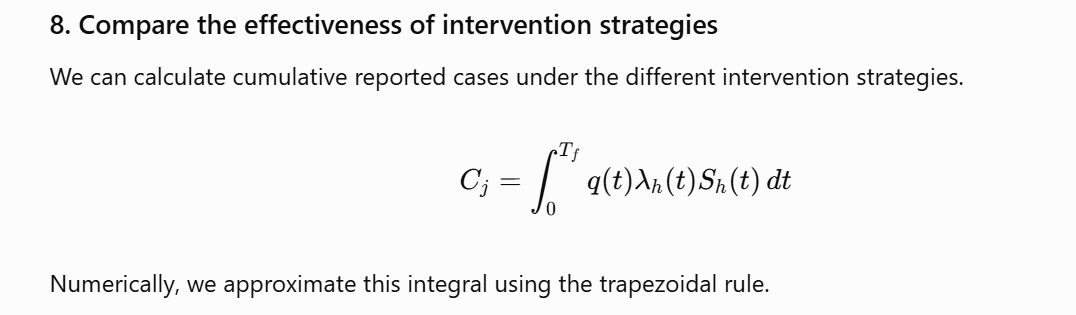

          Strategy  Cumulative reported cases  Reduction (%)
0  No intervention                  28.627844       0.000000
1         Moderate                  16.923802      40.883420
2        Intensive                   9.124979      68.125512
3         Seasonal                  21.411250      25.208304


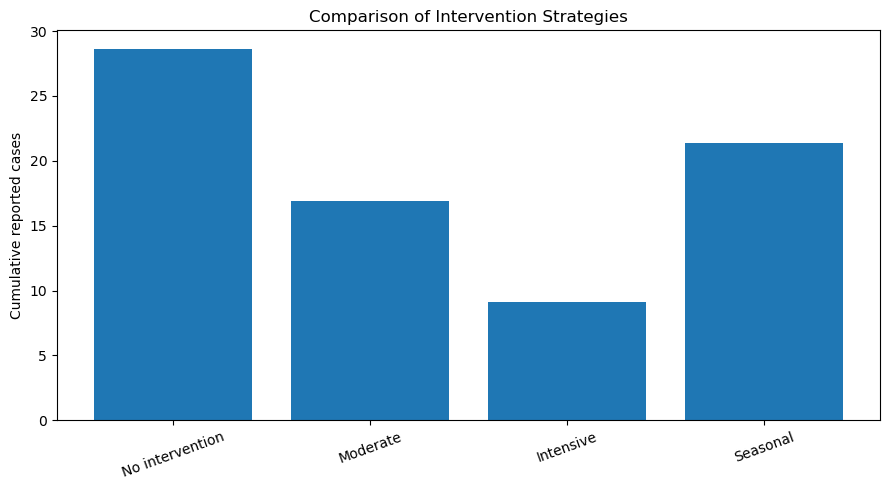

In [16]:

# =====================================================
# 14. INTERVENTION COMPARISON
# =====================================================

strategies = {
    "No intervention": no_control,
    "Moderate": moderate,
    "Intensive": intensive,
    "Seasonal": seasonal
}

summary = []

baseline_cases = np.trapezoid(
    no_control["Reported_cases"],
    no_control["Day"]
)

for name, result in strategies.items():

    total_cases = np.trapezoid(
        result["Reported_cases"],
        result["Day"]
    )

    reduction = (
        (baseline_cases-total_cases) /
        baseline_cases * 100
    )

    summary.append({
        "Strategy": name,
        "Cumulative reported cases": total_cases,
        "Reduction (%)": reduction
    })

summary_df = pd.DataFrame(summary)

print(summary_df)

# Plot intervention comparison
plt.figure(figsize=(9, 5))

plt.bar(
    summary_df["Strategy"],
    summary_df["Cumulative reported cases"]
)

plt.ylabel("Cumulative reported cases")

plt.title("Comparison of Intervention Strategies")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()


This produces a comparison of the four intervention scenarios.

Important: This is scenario analysis, not yet a solution to the full Pontryagin optimal control problem. It compares predefined intervention combinations. The true optimal-control implementation should subsequently solve the state and adjoint equations using forward-backward sweep or an optimal-control solver, subject to budget and intervention constraints.
9. Save the simulation outputs

In [17]:

# =====================================================
# 15. SAVE RESULTS
# =====================================================

moderate.to_csv(
    "malaria_mechanistic_results.csv",
    index=False
)

summary_df.to_csv(
    "malaria_intervention_comparison.csv",
    index=False
)

performance = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Hybrid AI-Mechanistic"
    ],
    "MAE": [
        mae,
        hybrid_mae
    ],
    "RMSE": [
        rmse,
        hybrid_rmse
    ],
    "R_squared": [
        r2,
        hybrid_r2
    ]
})

performance.to_csv(
    "malaria_model_performance.csv",
    index=False
)

print("All simulation results saved.")


All simulation results saved.


Malaria_AI_Model/
│
├── app.py
├── malaria_hybrid_model.py
├── malaria_surveillance_data.csv
└── requirements.txt

In [ ]:
1.How to Create app.py using Jupyter Notebook

Open anew Jupyter Notebook and create a new Python notebook.

In the first cell, paste the following:

Jupyter will create app.py in its current working directory.
2. Create requirements.txt
Create another cell in the same notebook and paste:

Your requirements.txt file is now created.
3. Save both files in Malaria_AI_Model

How to  Convert your Jupyter Notebook into Python code 
In Jupyter Notebook:
1. Open the notebook containing your malaria model.
2. Select File → Save and Export Notebook As → Executable Script (.py). The wording may vary slightly by Jupyter version.
3. Save the exported file as malaria_hybrid_model.py in your Malaria_AI_Model folder.
4. Open the Python file and check it.
Important:
- Remove notebook-only commands such as !pip install and %%writefile.
- Keep the Python imports and model functions.
- Avoid running all the plots automatically when importing the model into Streamlit. Put standalone execution code under if __name__ == "__main__": where appropriate.

Step 3: Create the Streamlit dashboard
In Jupyter, create a new notebook cell and run:

In [2]:
%%writefile app.py

import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

st.set_page_config(
    page_title="Malaria AI Surveillance Dashboard",
    page_icon="🦟",
    layout="wide"
)

st.title("🦟 Malaria AI and Mathematical Modelling Dashboard")
st.subheader("Precision Malaria Surveillance, Early Warning and Intervention")

data_file = Path("malaria_surveillance_data.csv")

if data_file.exists():
    df = pd.read_csv(data_file)

    st.success("Malaria surveillance dataset loaded successfully.")

    col1, col2, col3 = st.columns(3)

    col1.metric("Total recorded cases", int(df["Observed_cases"].sum()))
    col2.metric("Average daily cases", round(df["Observed_cases"].mean(), 2))
    col3.metric("Maximum daily cases", int(df["Observed_cases"].max()))

    st.subheader("Daily malaria cases")
    st.line_chart(df.set_index("Day")["Observed_cases"])

    st.subheader("Climate and malaria surveillance")

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(df["Day"], df["Temperature"], label="Temperature")
    ax.plot(df["Day"], df["Rainfall"], label="Rainfall")
    ax.set_xlabel("Day")
    ax.set_ylabel("Climate measurement")
    ax.legend()
    st.pyplot(fig)

    st.subheader("Surveillance data")
    st.dataframe(df, use_container_width=True)

    st.download_button(
        "Download surveillance dataset",
        data=df.to_csv(index=False),
        file_name="malaria_surveillance_data.csv",
        mime="text/csv"
    )

else:
    st.error("malaria_surveillance_data.csv was not found.")

st.caption(
    "Research prototype. The supplied surveillance dataset is synthetic "
    "and does not represent actual Kenyan malaria cases."
)

Overwriting app.py


This creates an initial dashboard for your surveillance dataset. It is not yet executing the SEIR–SEI simulation or trained AI predictor; those need to be connected to the dashboard using the functions in your model file.

Step 4: Create requirements.txt
Create another file named requirements.txt in the same folder.

Put the following in it:
streamlit
numpy
pandas
matplotlib
scipy
scikit-learn


These are the principal packages used by the dashboard and the model described earlier. Add any other package that your notebook imports. Streamlit Community Cloud uses this file to install the dependencies when deploying. How to create these files is shown above

These are the principal packages used by the dashboard and the model described earlier. Add any other package that your notebook imports. Streamlit Community Cloud uses this file to install the dependencies when deploying

Step 5: Test the dashboard on your computer
Open Anaconda Prompt and enter:

In [ ]:
cd "C:\Users\ICTServices\Malaria_AI_Model"

In [ ]:
pip install -r requirements.txt

Start the dashboard

In [ ]:
streamlit run app.py

Your browser should open the dashboard at

http://localhost:8501

Step 6: Upload the project to GitHub
You need a GitHub repository to host the application code.
1. Open GitHub.
2. Sign in to your account.
3. Click New repository.
4. Give it a name, for example:
Malaria_AI_Model
5. Choose Public if you want the repository publicly accessible.
6. Click Create repository.
7. Select Add file → Upload files.
8. Upload the four files:
   - app.py
   - malaria_hybrid_model.py
   - malaria_surveillance_data.csv
   - requirements.txt
9. Click Commit changes.
Your GitHub repository should look like this:
Malaria_AI_Model


app.py

malaria_hybrid_model.py

malaria_surveillance_data.csv

requirements.txt

Step 7: Deploy through Streamlit Community Cloud
Open https://share.streamlit.io.
1. Sign in using your GitHub account.
2. Authorise Streamlit to access your GitHub repository.
3. Click Create app.
4. Select Yup, I have an app.
5. Enter the deployment details as follows:
Deployment settings
Repositoryyour-github-username/Malaria_AI_Model
Replace your-github-username with your actual GitHub username.

Branchmain


Main file pathapp.py


App URLmalaria-ai-surveillance
Optional custom address, if available.

6. Click Deploy.

Streamlit will install your requirements and launch the application. When deployment succeeds, it provides a public address ending in .streamlit.app. 
Streamlit Docs+1

Step 8: Update your dashboard
Whenever you improve the model:
1. Edit the Python code in Jupyter or your code editor.
2. Save the updated .py file.
3. Upload the changed file to the same GitHub repository.
4. Commit the changes.
Streamlit Community Cloud will detect the GitHub update and redeploy the application. 
Streamlit Docs


Important: Connecting the actual malaria model
For your research, I recommend developing the dashboard in four connected sections:
1. Malaria surveillance data

Upload CSV files containing malaria cases, rainfall, temperature and humidity.


2. Mathematical transmission model

Simulate the SEIR–SEI human–mosquito model and compare intervention scenarios.


3. AI prediction

Integrate Random Forest, XGBoost or LSTM for malaria risk prediction and early warning.


4. Intervention decision support

Compare no intervention, moderate intervention, intensive intervention and seasonal intervention.